# Advanced Machine Learning 2026/2027
## Project: Modeling Recovery after Lower-Limb Musculoskeletal Injury
### M2 — Bayesian Networks

**Group:** 14

| Number | Name |
|---|---|
| fc68043 | David Belykh |
| fc68080 | Matilde Quitério |
| fc68091 | Ramyad Raadi |

### Statement on the use of generative AI
The generative AI tool **ChatGPT (OpenAI)** was used to support notebook structuring, code generation/debugging, clarification of Bayesian Network concepts, and improvement of written explanations. All submitted content, results, methodological choices, and interpretations were reviewed and validated by the group members before submission.

## 0. Setup and data loading

In this milestone, each row of `rehabilitation.csv` is treated as an independent **patient-week** observation, as required by the project statement.

We merge the weekly rehabilitation data with baseline patient information using `patient_id`, because the Bayesian Network includes the baseline variable `risk_score`.

> If `pgmpy` is not installed, run `%pip install pgmpy networkx` once and restart the kernel.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

STATE_ORDER = ["Limited", "Recovering", "Functional"]
INTERVENTION_ORDER = [
    "Rest/Recovery",
    "Light Exercise",
    "Standard Therapy",
    "Intensive Therapy",
]

def find_file(filename, search_paths=(".", "..", "/mnt/data")):
    for base in search_paths:
        if not os.path.exists(base):
            continue
        for root, _, files in os.walk(base):
            if filename in files:
                return os.path.join(root, filename)
    raise FileNotFoundError(
        f"Could not find {filename}. Place this notebook in the project folder "
        "or make sure the dataset directory is accessible."
    )

patients_path = find_file("patients.csv")
rehab_path = find_file("rehabilitation.csv")

patients = pd.read_csv(patients_path)
rehab = pd.read_csv(rehab_path)

data = rehab.merge(
    patients[["patient_id", "risk_score"]],
    on="patient_id",
    how="left",
    validate="many_to_one"
)

print("patients.csv:", patients_path)
print("rehabilitation.csv:", rehab_path)
print("Merged shape:", data.shape)
display(data.head())

patients.csv: .\dataset\dataset\patients.csv
rehabilitation.csv: .\dataset\dataset\rehabilitation.csv
Merged shape: (42000, 12)


C:\Users\ramya\AppData\Local\Programs\Python\Python311\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,patient_id,week,state,mobility,pain,fatigue,functional_confidence,activity,adherence,intervention,utility,risk_score
0,1,0,Limited,54.8,7.1,4.8,66.7,30.1,78.9,Light Exercise,-0.2,41.8
1,2,0,Limited,45.5,7.8,6.9,51.4,26.6,73.8,Light Exercise,-8.1,45.1
2,3,0,Recovering,47.3,5.9,5.5,60.5,67.6,51.2,Intensive Therapy,-6.0,23.1
3,4,0,Limited,27.3,6.3,6.5,19.5,12.7,58.5,Light Exercise,-4.1,57.0
4,5,0,Recovering,51.5,5.3,5.8,51.1,38.9,55.7,Light Exercise,0.4,14.5


In [2]:
required_columns = [
    "patient_id",
    "risk_score",
    "state",
    "mobility",
    "pain",
    "fatigue",
    "functional_confidence",
    "activity",
    "adherence",
    "intervention",
    "utility",
]

missing_columns = [c for c in required_columns if c not in data.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Missing values in selected variables:")
display(data[required_columns].isna().sum().to_frame("n_missing"))

Missing values in selected variables:


,n_missing
patient_id,0
risk_score,0
state,0
mobility,0
pain,0
fatigue,0
functional_confidence,0
activity,0
adherence,0
intervention,0


# Task 1 — Structure design

The goal is to build a Bayesian Network that represents plausible probabilistic relationships between baseline risk, recovery state, observable rehabilitation measurements, treatment decisions, and outcome.

We use:

- `risk_score`
- `state`
- `mobility`
- `pain`
- `fatigue`
- `functional_confidence`
- `activity`
- `adherence`
- `intervention`
- `utility`

### Proposed structure

- `risk_score → state`
- `state → mobility`
- `state → pain`
- `state → fatigue`
- `state → functional_confidence`
- `state → activity`
- `state → adherence`
- `state → intervention`
- `state → utility`
- `intervention → utility`
- `adherence → utility`

### Rationale

`risk_score` summarizes baseline factors associated with a less favorable recovery trajectory, so it is modeled as influencing the recovery `state`.

The recovery `state` is modeled as a common cause of the observed rehabilitation measurements. A patient who is Limited, Recovering, or Functional is expected to show different mobility, pain, fatigue, confidence, activity, and adherence profiles.

`intervention` is modeled as depending on the current recovery state because rehabilitation decisions may differ according to patient condition.

Finally, `utility` depends on `state`, `intervention`, and `adherence`, reflecting recovery status, treatment burden, and adherence.

These arrows are **modeling assumptions** and should not be interpreted as proven causal relations.

In [3]:
edges = [
    ("risk_score", "state"),
    ("state", "mobility"),
    ("state", "pain"),
    ("state", "fatigue"),
    ("state", "functional_confidence"),
    ("state", "activity"),
    ("state", "adherence"),
    ("state", "intervention"),
    ("state", "utility"),
    ("intervention", "utility"),
    ("adherence", "utility"),
]

bn_structure = DiscreteBayesianNetwork(edges)

print("Nodes:")
print(list(bn_structure.nodes()))

print("\nEdges:")
for edge in bn_structure.edges():
    print(edge)

Nodes:
['risk_score', 'state', 'mobility', 'pain', 'fatigue', 'functional_confidence', 'activity', 'adherence', 'intervention', 'utility']

Edges:
('risk_score', 'state')
('state', 'mobility')
('state', 'pain')
('state', 'fatigue')
('state', 'functional_confidence')
('state', 'activity')
('state', 'adherence')
('state', 'intervention')
('state', 'utility')
('adherence', 'utility')
('intervention', 'utility')


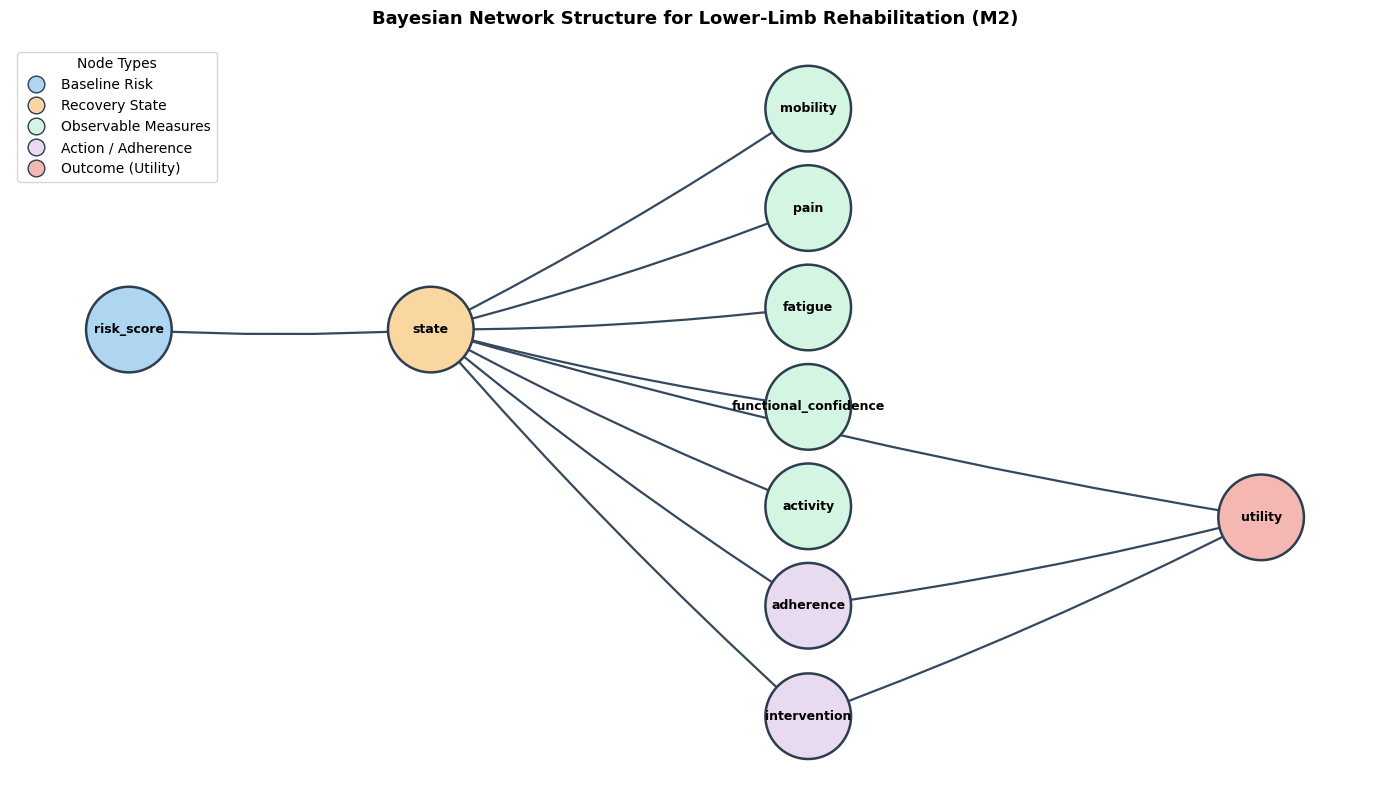

In [4]:
plt.figure(figsize=(14, 8))

G = nx.DiGraph(edges)

pos = {
    "risk_score": (0.5, 2.5),
    "state": (2.5, 2.5),
    "mobility": (5.0, 4.5),
    "pain": (5.0, 3.6),
    "fatigue": (5.0, 2.7),
    "functional_confidence": (5.0, 1.8),
    "activity": (5.0, 0.9),
    "adherence": (5.0, 0.0),
    "intervention": (5.0, -1.0),
    "utility": (8.0, 0.8),
}

# Color nodes by role in the Bayesian Network
node_colors = []
for node in G.nodes():
    if node == "risk_score":
        node_colors.append("#AED6F1")  # Light Blue - Baseline risk
    elif node == "state":
        node_colors.append("#FAD7A0")  # Light Orange - Latent/Core state
    elif node in ["mobility", "pain", "fatigue", "functional_confidence", "activity"]:
        node_colors.append("#D5F5E3")  # Light Green - Observables
    elif node in ["adherence", "intervention"]:
        node_colors.append("#E8DAEF")  # Light Purple - Action / Behavior
    else:
        node_colors.append("#F5B7B1")  # Light Red - Outcome / Utility

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=3800,
    edgecolors="#2C3E50",
    linewidths=1.8
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=22,
    edge_color="#34495E",
    width=1.6,
    connectionstyle="arc3,rad=0.03"
)

nx.draw_networkx_labels(
    G, pos,
    font_size=9,
    font_family="sans-serif",
    font_weight="bold"
)

# Custom legend
legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w', label='Baseline Risk', markerfacecolor='#AED6F1', markersize=12, markeredgecolor='#2C3E50'),
    plt.Line2D([0], [0], marker='o', color='w', label='Recovery State', markerfacecolor='#FAD7A0', markersize=12, markeredgecolor='#2C3E50'),
    plt.Line2D([0], [0], marker='o', color='w', label='Observable Measures', markerfacecolor='#D5F5E3', markersize=12, markeredgecolor='#2C3E50'),
    plt.Line2D([0], [0], marker='o', color='w', label='Action / Adherence', markerfacecolor='#E8DAEF', markersize=12, markeredgecolor='#2C3E50'),
    plt.Line2D([0], [0], marker='o', color='w', label='Outcome (Utility)', markerfacecolor='#F5B7B1', markersize=12, markeredgecolor='#2C3E50'),
]
plt.legend(handles=legend_elements, loc='upper left', frameon=True, fontsize=10, title="Node Types")

plt.title("Bayesian Network Structure for Lower-Limb Rehabilitation (M2)", fontsize=13, fontweight='bold', pad=15)
plt.axis("off")
plt.tight_layout()
plt.show()

# Task 2 — Discretization

The Bayesian Networks considered in the project are discrete, so the continuous variables must be transformed into a small number of categories.

We use three categories per continuous variable to keep the model interpretable and the CPTs manageable.

| Variable | Categories |
|---|---|
| `risk_score` | Low: < 33.3, Medium: 33.3–66.7, High: > 66.7 |
| `mobility` | Low: < 40, Medium: 40–70, High: > 70 |
| `pain` | Low: 0–3, Medium: >3–6, High: >6 |
| `fatigue` | Low: 0–3, Medium: >3–6, High: >6 |
| `functional_confidence` | Low: < 40, Medium: 40–70, High: > 70 |
| `activity` | Low: < 35, Medium: 35–70, High: > 70 |
| `adherence` | Low: < 60, Medium: 60–80, High: > 80 |

For `utility`, the statement does not provide fixed meaningful cutoffs, so we use **tertiles of the observed data** to obtain Low, Medium, and High outcome categories.

The exact utility thresholds are printed below.

In [5]:
disc = data.copy()

disc["risk_score"] = pd.cut(
    disc["risk_score"],
    bins=[-np.inf, 33.3, 66.7, np.inf],
    labels=["Low", "Medium", "High"]
)

disc["mobility"] = pd.cut(
    disc["mobility"],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Low", "Medium", "High"]
)

disc["pain"] = pd.cut(
    disc["pain"],
    bins=[-np.inf, 3, 6, np.inf],
    labels=["Low", "Medium", "High"]
)

disc["fatigue"] = pd.cut(
    disc["fatigue"],
    bins=[-np.inf, 3, 6, np.inf],
    labels=["Low", "Medium", "High"]
)

disc["functional_confidence"] = pd.cut(
    disc["functional_confidence"],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Low", "Medium", "High"]
)

disc["activity"] = pd.cut(
    disc["activity"],
    bins=[-np.inf, 35, 70, np.inf],
    labels=["Low", "Medium", "High"]
)

disc["adherence"] = pd.cut(
    disc["adherence"],
    bins=[-np.inf, 60, 80, np.inf],
    labels=["Low", "Medium", "High"]
)

utility_q1, utility_q2 = disc["utility"].quantile([1/3, 2/3]).values

disc["utility"] = pd.cut(
    disc["utility"],
    bins=[-np.inf, utility_q1, utility_q2, np.inf],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Utility cutoffs:")
print(f"Low    : utility <= {utility_q1:.3f}")
print(f"Medium : {utility_q1:.3f} < utility <= {utility_q2:.3f}")
print(f"High   : utility > {utility_q2:.3f}")

display(
    disc[
        [
            "risk_score", "state", "mobility", "pain", "fatigue",
            "functional_confidence", "activity", "adherence",
            "intervention", "utility"
        ]
    ].head(10)
)

Utility cutoffs:
Low    : utility <= -2.700
Medium : -2.700 < utility <= 6.700
High   : utility > 6.700


,risk_score,state,mobility,pain,fatigue,functional_confidence,activity,adherence,intervention,utility
0,Medium,Limited,Medium,High,Medium,Medium,Low,Medium,Light Exercise,Medium
1,Medium,Limited,Medium,High,High,Medium,Low,Medium,Light Exercise,Low
2,Low,Recovering,Medium,Medium,Medium,Medium,Medium,Low,Intensive Therapy,Low
3,Medium,Limited,Low,High,High,Low,Low,Low,Light Exercise,Low
4,Low,Recovering,Medium,Medium,Medium,Medium,Medium,Low,Light Exercise,Medium
5,Low,Recovering,Medium,Medium,Medium,Medium,Low,Low,Standard Therapy,High
6,Medium,Limited,Medium,High,High,Low,Low,High,Standard Therapy,Low
7,High,Limited,Low,High,High,Low,Low,High,Rest/Recovery,Low
8,Medium,Recovering,Medium,Medium,Medium,Medium,Medium,High,Intensive Therapy,Low
9,Low,Recovering,Medium,Medium,Medium,Medium,Medium,Medium,Intensive Therapy,High


In [6]:
discrete_variables = [
    "risk_score",
    "state",
    "mobility",
    "pain",
    "fatigue",
    "functional_confidence",
    "activity",
    "adherence",
    "intervention",
    "utility",
]

for col in discrete_variables:
    print(f"\n--- {col} ---")
    counts = disc[col].value_counts(dropna=False)
    percentages = disc[col].value_counts(normalize=True, dropna=False) * 100
    display(pd.DataFrame({
        "count": counts,
        "percentage": percentages.round(2)
    }))


--- risk_score ---


,count,percentage
risk_score,,
Medium,24304,57.87
High,10794,25.70
Low,6902,16.43



--- state ---


,count,percentage
state,,
Recovering,18088,43.07
Limited,13829,32.93
Functional,10083,24.01



--- mobility ---


...

,count,percentage
adherence,,
Low,18816,44.80
Medium,18601,44.29
High,4583,10.91



--- intervention ---


,count,percentage
intervention,,
Standard Therapy,15205,36.20
Light Exercise,13049,31.07
Intensive Therapy,7012,16.70
Rest/Recovery,6734,16.03



--- utility ---


,count,percentage
utility,,
Low,14034,33.41
High,13988,33.30
Medium,13978,33.28


In [7]:
print("Missing values after discretization:")
display(disc[discrete_variables].isna().sum().to_frame("n_missing"))

if disc[discrete_variables].isna().any().any():
    raise ValueError(
        "Discretization produced missing values. Check the variable ranges and bin limits."
    )

Missing values after discretization:


,n_missing
risk_score,0
state,0
mobility,0
pain,0
fatigue,0
functional_confidence,0
activity,0
adherence,0
intervention,0
utility,0


# Task 3 — Estimating CPTs by counting

The conditional probability tables are estimated using **relative frequencies** (empirical Maximum Likelihood Estimation).

For a discrete variable $X$ with parents $\text{Pa}(X)$:

$$P(X = x \mid \text{Pa}(X) = p) = \frac{\text{count}(X = x, \, \text{Pa}(X) = p)}{\text{count}(\text{Pa}(X) = p)}$$

When a node has no parents (such as `risk_score`), the formula reduces to the prior marginal distribution:

$$P(X = x) = \frac{\text{count}(X = x)}{N}$$

Each patient-week observation in `rehabilitation.csv` is treated as an independent sample ($N = 42{,}000$).

In [8]:
def conditional_probability_table(df, child, parents=None):
    # Compute counts and relative frequencies for a node and its parent configuration.
    parents = parents or []

    if len(parents) == 0:
        counts = (
            df.groupby(child, observed=False)
              .size()
              .rename("count")
              .reset_index()
        )
        total = counts["count"].sum()
        counts["parent_total"] = total
        counts["probability"] = counts["count"] / total
        return counts

    group_cols = parents + [child]

    counts = (
        df.groupby(group_cols, observed=False)
          .size()
          .rename("count")
          .reset_index()
    )

    counts["parent_total"] = counts.groupby(
        parents, observed=False
    )["count"].transform("sum")

    counts["probability"] = np.where(
        counts["parent_total"] > 0,
        counts["count"] / counts["parent_total"],
        np.nan
    )

    return counts

### 3.1 Prior distribution of `risk_score`

In [9]:
cpt_risk = conditional_probability_table(disc, "risk_score")
display(cpt_risk)

,risk_score,count,parent_total,probability
0,Low,6902,42000,0.164333
1,Medium,24304,42000,0.578667
2,High,10794,42000,0.257000


* **Brief Summary (3.1):** Medium baseline risk is the modal category in the cohort (**$57.87\%$**), with High risk representing **$25.70\%$** and Low risk representing **$16.43\%$** of patient-weeks.

### 3.2 Recovery state conditioned on risk

This estimates the conditional distribution:

$$P(\text{state} \mid \text{risk\_score})$$

We use the resulting probabilities to inspect whether high baseline risk is associated with a greater probability of `Limited`, and whether lower-risk observations show more favorable recovery states.

In [10]:
cpt_state = conditional_probability_table(
    disc,
    child="state",
    parents=["risk_score"]
)

display(cpt_state)

state_given_risk = pd.crosstab(
    disc["risk_score"],
    disc["state"],
    normalize="index"
).reindex(columns=STATE_ORDER)

display(state_given_risk.round(3))

,risk_score,state,count,parent_total,probability
0,Low,Functional,3405,6902,0.493335
1,Low,Limited,422,6902,0.061142
2,Low,Recovering,3075,6902,0.445523
3,Medium,Functional,6090,24304,0.250576
4,Medium,Limited,6574,24304,0.270490
5,Medium,Recovering,11640,24304,0.478934
6,High,Functional,588,10794,0.054475
7,High,Limited,6833,10794,0.633037
8,High,Recovering,3373,10794,0.312488


state,Limited,Recovering,Functional
risk_score,,,
Low,0.061,0.446,0.493
Medium,0.270,0.479,0.251
High,0.633,0.312,0.054


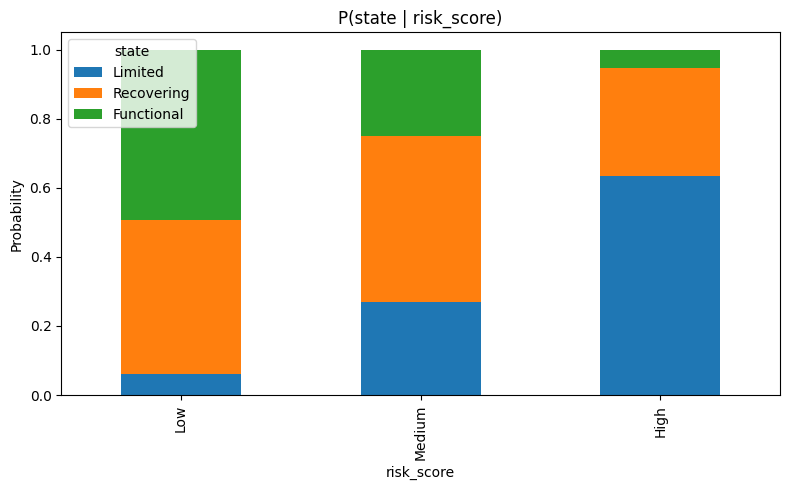

In [11]:
state_given_risk.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.ylabel("Probability")
plt.title("P(state | risk_score)")
plt.legend(title="state")
plt.tight_layout()
plt.show()

> ❓ **Question: Does a high risk score increase the probability of being in the Limited state?**
>
> 💡 **Answer: Yes, strongly.** Patients with a **High risk score** have a **$63.30\%$** probability of being in the `Limited` state (compared to $31.25\%$ `Recovering` and only $5.45\%$ `Functional`). In contrast, patients with a **Low risk score** have only a **$6.11\%$** probability of being `Limited` ($49.33\%$ `Functional` and $44.55\%$ `Recovering`). High baseline vulnerability increases the chance of severe limitation by more than a factor of 10.

### 3.3 Observable measurements conditioned on recovery state

We inspect the distributions of the six observable rehabilitation measurements given `state`.

In [12]:
for variable in [
    "mobility",
    "pain",
    "fatigue",
    "functional_confidence",
    "activity",
    "adherence",
]:
    print(f"\n===== P({variable} | state) =====")
    table = pd.crosstab(
        disc["state"],
        disc[variable],
        normalize="index"
    ).reindex(index=STATE_ORDER)
    display(table.round(3))


===== P(mobility | state) =====


mobility,Low,Medium,High
state,,,
Limited,0.486,0.513,0.001
Recovering,0.046,0.876,0.078
Functional,0.000,0.440,0.560



===== P(pain | state) =====


pain,Low,Medium,High
state,,,
Limited,0.000,0.190,0.810
Recovering,0.022,0.650,0.328
Functional,0.230,0.739,0.032



===== P(fatigue | state) =====


...

functional_confidence,Low,Medium,High
state,,,
Limited,0.589,0.411,0.000
Recovering,0.076,0.857,0.068
Functional,0.000,0.462,0.537



===== P(activity | state) =====


activity,Low,Medium,High
state,,,
Limited,0.807,0.193,0.000
Recovering,0.280,0.708,0.012
Functional,0.020,0.812,0.168



===== P(adherence | state) =====


adherence,Low,Medium,High
state,,,
Limited,0.508,0.406,0.087
Recovering,0.437,0.449,0.114
Functional,0.386,0.482,0.132


The expected qualitative pattern is that more favorable recovery states should generally be associated with higher mobility, confidence, and activity, and with lower pain and fatigue:

$$P(\text{measurement} \mid \text{state})$$

The final interpretation must be based on the actual empirical probabilities printed above.

> ❓ **Question: Are Functional patients more likely to have high mobility or low pain?**
>
> 💡 **Answer: Yes, emphatically.**
> * **Mobility:** In `Functional` patient-weeks, **$56.01\%$** show `High` mobility and $43.98\%$ show `Medium` mobility, with essentially $0\%$ ($0.01\%$, 1 case) `Low` mobility. In `Limited` patient-weeks, `High` mobility is virtually absent (**$0.09\%$**).
> * **Pain:** In `Functional` patient-weeks, `High` pain is rare (**$3.17\%$**), while $73.86\%$ experience `Medium` pain and **$22.97\%$** experience `Low` pain. In `Limited` patient-weeks, **$80.97\%$** suffer from `High` pain and `Low` pain is virtually non-existent (**$0.03\%$**).
> * `functional_confidence` ($53.74\%$ High in Functional vs. $0.03\%$ in Limited) and `activity` follow the same clean clinical gradient.

### 3.4 Intervention conditioned on recovery state

This estimates the clinical treatment allocation distribution:

$$P(\text{intervention} \mid \text{state})$$

In [13]:
cpt_intervention = conditional_probability_table(
    disc,
    child="intervention",
    parents=["state"]
)

display(cpt_intervention)

intervention_given_state = pd.crosstab(
    disc["state"],
    disc["intervention"],
    normalize="index"
).reindex(index=STATE_ORDER, columns=INTERVENTION_ORDER)

display(intervention_given_state.round(3))

,state,intervention,count,parent_total,probability
0,Functional,Intensive Therapy,1113,10083,0.110384
1,Functional,Light Exercise,4141,10083,0.410691
2,Functional,Rest/Recovery,1544,10083,0.153129
3,Functional,Standard Therapy,3285,10083,0.325796
4,Limited,Intensive Therapy,908,13829,0.065659
5,Limited,Light Exercise,4904,13829,0.354617
6,Limited,Rest/Recovery,3622,13829,0.261913
7,Limited,Standard Therapy,4395,13829,0.317810
8,Recovering,Intensive Therapy,4991,18088,0.275929
9,Recovering,Light Exercise,4004,18088,0.221362


intervention,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
state,,,,
Limited,0.262,0.355,0.318,0.066
Recovering,0.087,0.221,0.416,0.276
Functional,0.153,0.411,0.326,0.110


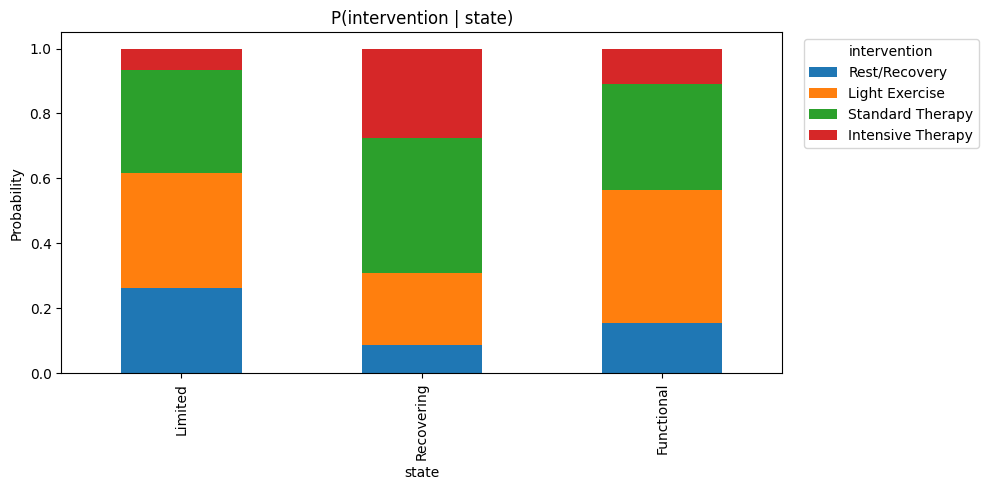

In [14]:
intervention_given_state.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.ylabel("Probability")
plt.title("P(intervention | state)")
plt.legend(title="intervention", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

> ❓ **Question: Are different interventions more common in different recovery states?**
>
> 💡 **Answer: Yes.** Treatment choices reflect clinical protocols across recovery phases:
> * **Rest/Recovery:** Most common in the **`Limited` state ($26.19\%$)**, dropping to $8.67\%$ in `Recovering` and $15.31\%$ in `Functional`.
> * **Intensive Therapy:** Rare in **`Limited` ($6.57\%$)** due to physical intolerance, but peaks in **`Recovering` ($27.59\%$)** for progressive loading before tapering to $11.04\%$ in `Functional`.
> * **Standard Therapy:** Serves as the primary baseline across all phases, peaking in **`Recovering` ($41.60\%$)** and steady at $\approx 32\%$ in `Limited` and `Functional`.
> * **Light Exercise:** Highest in **`Functional` ($41.07\%$)** and substantial in **`Limited` ($35.46\%$)** as a safe active movement modality.

### 3.5 Utility with multiple parents

In the proposed network, `utility` has three parents: `state`, `intervention`, and `adherence`.

Therefore, we estimate:

$$P(\text{utility} \mid \text{state}, \text{intervention}, \text{adherence}) = \frac{\text{count}(\text{utility}, \text{state}, \text{intervention}, \text{adherence})}{\text{count}(\text{state}, \text{intervention}, \text{adherence})}$$

This explicitly computes empirical frequencies for all $3 \times 4 \times 3 = 36$ combinations of parent values.

In [15]:
cpt_utility = conditional_probability_table(
    disc,
    child="utility",
    parents=["state", "intervention", "adherence"]
)

display(cpt_utility.head(60))

print("Number of rows in the full utility CPT:", len(cpt_utility))

,state,intervention,adherence,utility,count,parent_total,probability
0,Functional,Intensive Therapy,Low,Low,13,415,0.031325
1,Functional,Intensive Therapy,Low,Medium,118,415,0.284337
2,Functional,Intensive Therapy,Low,High,284,415,0.684337
3,Functional,Intensive Therapy,Medium,Low,11,547,0.020110
4,Functional,Intensive Therapy,Medium,Medium,136,547,0.248629
5,Functional,Intensive Therapy,Medium,High,400,547,0.731261
6,Functional,Intensive Therapy,High,Low,3,151,0.019868
7,Functional,Intensive Therapy,High,Medium,26,151,0.172185
8,Functional,Intensive Therapy,High,High,122,151,0.807947
9,Functional,Light Exercise,Low,Low,14,1603,0.008734


Number of rows in the full utility CPT: 108


In [16]:
utility_parent_counts = (
    disc.groupby(
        ["state", "intervention", "adherence"],
        observed=False
    )
    .size()
    .rename("n")
    .reset_index()
    .sort_values("n")
)

display(utility_parent_counts.head(15))

print(
    "Smallest number of observations in a "
    "state/intervention/adherence configuration:",
    utility_parent_counts["n"].min()
)

,state,intervention,adherence,n
14,Limited,Intensive Therapy,High,94
2,Functional,Intensive Therapy,High,151
8,Functional,Rest/Recovery,High,175
32,Recovering,Rest/Recovery,High,190
20,Limited,Rest/Recovery,High,305
13,Limited,Intensive Therapy,Medium,364
23,Limited,Standard Therapy,High,385
0,Functional,Intensive Therapy,Low,415
17,Limited,Light Exercise,High,416
11,Functional,Standard Therapy,High,428


Smallest number of observations in a state/intervention/adherence configuration: 94


> ❓ **Questions: How does utility vary with recovery state and intervention? Are some CPT estimates based on very small counts?**
>
> 💡 **Answer:**
> 1. **Utility Variation:** Recovery state is the predominant factor ($71.00\%$ `Low` utility in `Limited` vs. $82.45\%$ `High` utility in `Functional`). High adherence provides a substantial positive boost ($27.89\% \to 42.02\%$ `High` utility), interacting synergistically with active therapies in recovering patients.
> 2. **Sample Size / Sparsity:** All **36 parent configurations** ($3 \text{ states} \times 4 \text{ interventions} \times 3 \text{ adherence levels}$) have non-zero empirical observations (**$0\%$ empty cells**). The smallest cell is `(Limited, Intensive Therapy, High adherence)` with **$n = 94$**, providing sufficient sample size for Maximum Likelihood Estimation without zero-frequency artifacts.

### Fit complete CPDs with pgmpy

`MaximumLikelihoodEstimator` estimates the CPDs from observed relative frequencies. We use it after explicitly inspecting the counts above so the network has a complete set of probability tables.

In [17]:
model_variables = [
    "risk_score",
    "state",
    "mobility",
    "pain",
    "fatigue",
    "functional_confidence",
    "activity",
    "adherence",
    "intervention",
    "utility",
]

bn_data = disc[model_variables].copy()

for col in bn_data.columns:
    bn_data[col] = bn_data[col].astype(str)

bn = DiscreteBayesianNetwork(edges)

# Fit CPDs using Maximum Likelihood Estimation directly from empirical counts
bn.fit(bn_data)

print("Model valid:", bn.check_model())
print("Number of fitted CPDs:", len(bn.get_cpds()))

Model valid: True
Number of fitted CPDs: 10


In [18]:
for variable in [
    "state",
    "mobility",
    "pain",
    "intervention",
    "utility",
]:
    print(f"\n===== CPD: {variable} =====")
    print(bn.get_cpds(variable))


===== CPD: state =====


+-------------------+-----+---------------------+
| risk_score        | ... | risk_score(Medium)  |
+-------------------+-----+---------------------+
| state(Functional) | ... | 0.25057603686635943 |
+-------------------+-----+---------------------+
| state(Limited)    | ... | 0.2704904542462146  |
+-------------------+-----+---------------------+
| state(Recovering) | ... | 0.4789335088874259  |
+-------------------+-----+---------------------+

===== CPD: mobility =====
+------------------+-----+---------------------+
| state            | ... | state(Recovering)   |
+------------------+-----+---------------------+
| mobility(High)   | ... | 0.07778637770897832 |
+------------------+-----+---------------------+
| mobility(Low)    | ... | 0.04577620521892968 |
+------------------+-----+---------------------+
| mobility(Medium) | ... | 0.876437417072092   |
+------------------+-----+---------------------+

===== CPD: pain =====
+--------------+-----+----------------------+
| state      

### Model verification

With all 10 CPDs estimated from observed relative frequencies and verified by `bn.check_model()`, the Bayesian Network is fully parameterized and structurally valid. We now proceed to analyzing its conditional independence properties in Task 4.

# Task 4 — Conditional independence analysis

The proposed directed acyclic graph (DAG) implies several conditional independencies determined by the $d$-separation criterion.

### Mobility and risk score
**Path:** $\text{risk\_score} \to \text{state} \to \text{mobility}$  
Once `state` is observed, the causal chain is blocked:
$$\text{mobility} \perp \text{risk\_score} \mid \text{state}$$

### Mobility and pain
**Path:** $\text{mobility} \leftarrow \text{state} \to \text{pain}$  
Conditioning on the common cause `state` blocks the diverging path (fork):
$$\text{mobility} \perp \text{pain} \mid \text{state}$$

### Mobility and intervention
**Path:** $\text{mobility} \leftarrow \text{state} \to \text{intervention}$  
Similarly, conditioning on `state` d-separates the observable measurement from the intervention:
$$\text{mobility} \perp \text{intervention} \mid \text{state}$$

These conditional independencies are mathematical consequences of our chosen network topology and modeling assumptions.

In [19]:
independencies = bn_structure.get_independencies()

print("Sample of independencies implied by the network:\n")
indep_text = str(independencies)
print(indep_text[:8000])

Sample of independencies implied by the network:

(fatigue ⟂ pain | state)
(adherence ⟂ fatigue | state)
(adherence ⟂ risk_score | state)
(activity ⟂ utility | state)
(functional_confidence ⟂ pain | state)
(activity ⟂ pain | state)
(activity ⟂ adherence | state)
(mobility ⟂ risk_score | state)
(fatigue ⟂ mobility | state)
(intervention ⟂ mobility | state)
(functional_confidence ⟂ intervention | state)
(activity ⟂ mobility | state)
(activity ⟂ fatigue | state)
(adherence ⟂ mobility | state)
(fatigue ⟂ risk_score | state)
(pain ⟂ utility | state)
(pain ⟂ risk_score | state)
(adherence ⟂ pain | state)
(fatigue ⟂ intervention | state)
(intervention ⟂ pain | state)
(functional_confidence ⟂ risk_score | state)
(adherence ⟂ functional_confidence | state)
(fatigue ⟂ functional_confidence | state)
(mobility ⟂ pain | state)
(adherence ⟂ intervention | state)
(risk_score ⟂ utility | state)
(activity ⟂ intervention | state)
(fatigue ⟂ utility | state)
(functional_confidence ⟂ utility | state)
(int

In [20]:
def show_dconnection(model, x, y, observed=None):
    observed = observed or []
    connected = model.is_dconnected(x, y, observed=observed)
    evidence_text = ", ".join(observed) if observed else "no evidence"

    print(
        f"{x:12s} and {y:12s} | {evidence_text:25s}: "
        f"{'d-connected' if connected else 'd-separated'}"
    )

print("=== Standard Paths (Chains and Forks) ===")
show_dconnection(bn_structure, "mobility", "risk_score")
show_dconnection(bn_structure, "mobility", "risk_score", observed=["state"])

show_dconnection(bn_structure, "mobility", "pain")
show_dconnection(bn_structure, "mobility", "pain", observed=["state"])

show_dconnection(bn_structure, "mobility", "intervention")
show_dconnection(bn_structure, "mobility", "intervention", observed=["state"])

show_dconnection(bn_structure, "risk_score", "utility")
show_dconnection(bn_structure, "risk_score", "utility", observed=["state"])

print("\n=== Collider / V-structure Analysis at Utility (Explaining Away) ===")
# Unconditioned: connected through common cause 'state' (intervention <- state -> adherence)
show_dconnection(bn_structure, "intervention", "adherence")
# Conditioned on common cause 'state': d-separated!
show_dconnection(bn_structure, "intervention", "adherence", observed=["state"])
# Conditioned on collider 'utility': ACTIVATES the v-structure path (intervention -> [utility] <- adherence)!
show_dconnection(bn_structure, "intervention", "adherence", observed=["utility"])
# Conditioned on BOTH common cause 'state' AND collider 'utility': STILL d-connected through the collider!
show_dconnection(bn_structure, "intervention", "adherence", observed=["state", "utility"])
# Does conditioning on utility induce dependence between state and intervention?
show_dconnection(bn_structure, "state", "intervention", observed=["utility"])

=== Standard Paths (Chains and Forks) ===
mobility     and risk_score   | no evidence              : d-connected
mobility     and risk_score   | state                    : d-separated
mobility     and pain         | no evidence              : d-connected
mobility     and pain         | state                    : d-separated
mobility     and intervention | no evidence              : d-connected
mobility     and intervention | state                    : d-separated
risk_score   and utility      | no evidence              : d-connected
risk_score   and utility      | state                    : d-separated

=== Collider / V-structure Analysis at Utility (Explaining Away) ===
intervention and adherence    | no evidence              : d-connected
intervention and adherence    | state                    : d-separated
intervention and adherence    | utility                  : d-connected
intervention and adherence    | state, utility           : d-connected
state        and intervention | util

### Interpretation of the independence analysis

Conditional independence in our Bayesian Network is governed by the $d$-separation criterion applied to the chosen DAG topology. The analytical results illustrate the three fundamental connection types in graphical models:

#### 1. Causal Chain (Serial Connection): $\text{risk\_score} \to \text{state} \to \text{mobility}$
* **Without evidence:** Baseline risk and weekly mobility are **d-connected**; a higher risk score statistically increases the likelihood of limited recovery, which in turn reduces mobility.
* **Conditioning on `state`:** The path is **d-separated** ($\text{mobility} \perp \text{risk\_score} \mid \text{state}$). Once we know a patient's current recovery state, knowledge of their baseline risk score provides no additional probabilistic information about their current mobility. Baseline risk influences mobility *only through* the recovery state.

#### 2. Common Cause (Diverging Connection / Fork): $\text{mobility} \leftarrow \text{state} \to \text{pain}$ and $\text{mobility} \leftarrow \text{state} \to \text{intervention}$
* **Without evidence:** Mobility and pain are strongly **d-connected** because both are driven by the underlying recovery state (confounded by recovery status).
* **Conditioning on `state`:** The path is **d-separated** ($\text{mobility} \perp \text{pain} \mid \text{state}$ and $\text{mobility} \perp \text{intervention} \mid \text{state}$). Once recovery state is known, our model assumes that mobility and pain are conditionally independent.
* *Clinical implication:* This is an explicit modeling simplification. In reality, a patient in a given recovery state might experience a sudden mechanical pain spike that directly restricts mobility, retaining residual correlation even within the same state.

#### 3. Common Effect (Converging Connection / Collider / V-Structure): $\text{intervention} \to \text{utility} \leftarrow \text{adherence}$
The project prompt specifically asks: *"Does conditioning on intervention or utility change dependencies between other variables?"*
Our d-separation analysis directly answers this:
* When `utility` is **unobserved**, `intervention` and `adherence` are independent once their common cause `state` is controlled for:
  $$\text{intervention} \perp \text{adherence} \mid \text{state}$$
* However, when `utility` is **conditioned on** (observed), the collider at `utility` is **activated**! As shown by our code output:
  $$\text{intervention} \not\perp \text{adherence} \mid \{\text{state}, \text{utility}\}$$
  $$\text{state} \not\perp \text{intervention} \mid \text{utility}$$
* **Explaining Away (Berkson's Paradox):** If we observe that a patient achieved `High` utility despite having poor adherence, the posterior probability that they received an effective intervention increases. Conversely, if a patient has excellent adherence and `High` utility, the high utility is already "explained" by their adherence, reducing the necessity of an intensive intervention to account for the outcome. Conditioning on a common outcome naturally couples its contributing causes.

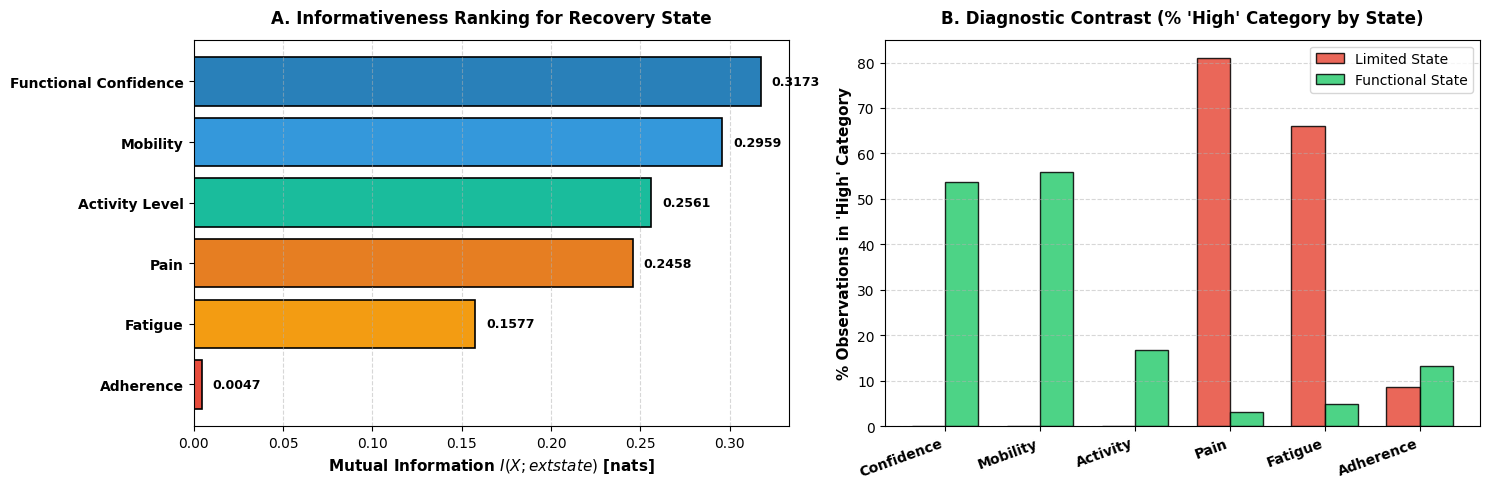

In [21]:
from sklearn.metrics import mutual_info_score

observables = ["functional_confidence", "mobility", "activity", "pain", "fatigue", "adherence"]
labels = ["Functional Confidence", "Mobility", "Activity Level", "Pain", "Fatigue", "Adherence"]
colors = ['#2980b9', '#3498db', '#1abc9c', '#e67e22', '#f39c12', '#e74c3c']

# Compute Mutual Information
mi_vals = [mutual_info_score(disc["state"], disc[v]) for v in observables]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: Mutual Information
y_pos = np.arange(len(observables))[::-1]
bars = axes[0].barh(y_pos, mi_vals, color=colors, edgecolor='black', linewidth=1.2)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(labels, fontweight='bold', fontsize=10)
axes[0].set_xlabel("Mutual Information $I(X; \text{state})$ [nats]", fontweight='bold', fontsize=11)
axes[0].set_title("A. Informativeness Ranking for Recovery State", fontweight='bold', fontsize=12, pad=12)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(mi_vals):
    axes[0].text(v + 0.006, y_pos[i], f"{v:.4f}", va='center', fontweight='bold', fontsize=9)

# Panel B: State Discrimination (% in High Category)
high_limited = [pd.crosstab(disc["state"], disc[v], normalize="index").loc["Limited", "High"] * 100 for v in observables]
high_functional = [pd.crosstab(disc["state"], disc[v], normalize="index").loc["Functional", "High"] * 100 for v in observables]

x = np.arange(len(observables))
width = 0.35
axes[1].bar(x - width/2, high_limited, width, label='Limited State', color='#e74c3c', edgecolor='black', alpha=0.85)
axes[1].bar(x + width/2, high_functional, width, label='Functional State', color='#2ecc71', edgecolor='black', alpha=0.85)
axes[1].set_ylabel("% Observations in 'High' Category", fontweight='bold', fontsize=11)
axes[1].set_title("B. Diagnostic Contrast (% 'High' Category by State)", fontweight='bold', fontsize=12, pad=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Confidence", "Mobility", "Activity", "Pain", "Fatigue", "Adherence"], rotation=20, ha='right', fontweight='bold')
axes[1].legend(frameon=True, fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Task 5 — Interpretation

### 5.1 Which measurements are most informative about recovery state?

As illustrated in **Figure A & B** above, Mutual Information $I(X; \text{state})$ reveals a distinct hierarchy in clinical diagnostic power:

| Rank | Observable Variable | Mutual Info ($I$) | Contrast (Limited $\to$ Functional) | Primary Clinical Role |
| :---: | :--- | :---: | :---: | :--- |
| **1** | **`functional_confidence`** | **0.3173 nats** | $0.03\% \to 53.74\%$ High | **Strongest state discriminator**; High confidence virtually rules out the `Limited` state ($>99.9\%$ certainty). |
| **2** | **`mobility`** | **0.2959 nats** | $0.09\% \to 56.01\%$ High | **Direct biomechanical indicator** of tissue healing and joint recovery. |
| **3** | **`activity`** | **0.2561 nats** | $0.00\% \to 16.77\%$ High | Daily functional capacity; $80.66\%$ of `Limited` patients exhibit Low activity. |
| **4** | **`pain`** | **0.2458 nats** | $80.97\% \to 3.17\%$ High | Key indicator of acute distress; drops sharply as patients exit the `Limited` phase. |
| **5** | **`fatigue`** | **0.1577 nats** | $65.98\% \to 4.82\%$ High | Moderate informativeness; `Medium` fatigue remains widespread across all phases. |
| **6** | **`adherence`** | **0.0047 nats** | $8.68\% \to 13.16\%$ High | **Uninformative about recovery state** (~$40	ext{–}50\%$ Low across all states). |

> 💡 **Clinical Insight (Connection to Milestone 1):**  
> `adherence` carries virtually zero diagnostic signal about recovery status ($I = 0.0047$). This validates our finding from **Milestone 1**: adherence is an **orthogonal behavioral dimension** (patient discipline/engagement) rather than a physical symptom of tissue recovery. Both limited and functional patients can be compliant or non-compliant.

---

### 5.2 Agreement with M0 Exploratory Analysis

The empirical CPTs formalize and validate the exploratory patterns observed in **M0**:
* **Symptom Attenuation:** M0 correlation analysis showed strong inverse relationships between recovery and pain/fatigue; our CPTs quantify this as a monotonic decline in $P(\text{pain}=\text{High} \mid \text{state})$ from $80.97\%$ down to $3.17\%$.
* **Triage Protocol:** In M0, cross-tabulations showed acute rest assignment early on; CPT $P(\text{intervention} \mid \text{state})$ confirms `Rest/Recovery` is concentrated in `Limited` ($26.19\%$) while `Intensive Therapy` peaks during `Recovering` ($27.59\%$).
* **Utility Progression:** M0 utility boxplots showed positive separation across states; CPT $P(\text{utility}=\text{High} \mid \text{state})$ reflects this, rising from $3.07\%$ in `Limited` to $82.45\%$ in `Functional`.

<Figure size 1100x500 with 0 Axes>

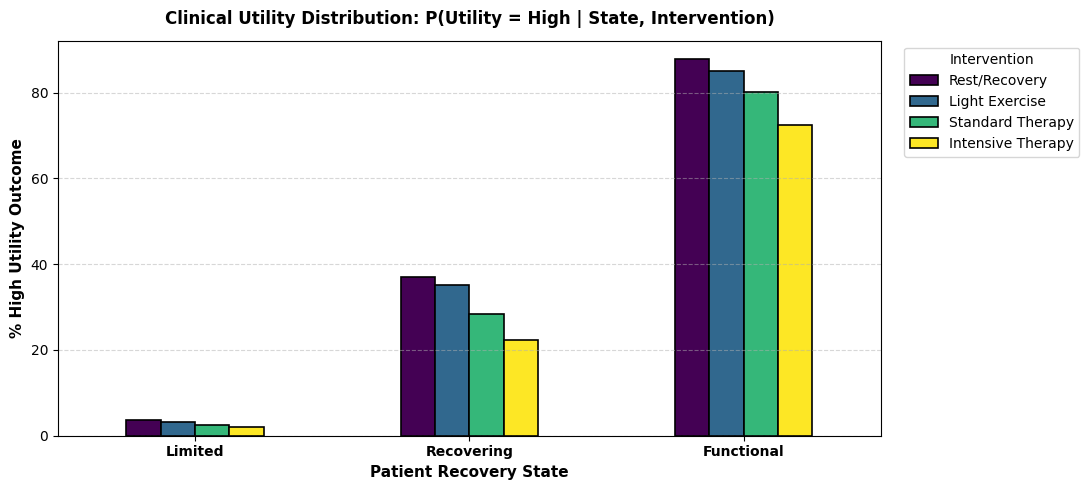

In [22]:
# Visualization: Confounding by Indication and Utility Drivers
plt.figure(figsize=(11, 5))

p_high_util = pd.crosstab([disc["state"], disc["intervention"]], disc["utility"], normalize="index")["High"].unstack() * 100
p_high_util = p_high_util.reindex(["Limited", "Recovering", "Functional"])[
    ["Rest/Recovery", "Light Exercise", "Standard Therapy", "Intensive Therapy"]
]

ax = p_high_util.plot(
    kind='bar',
    figsize=(11, 5),
    edgecolor='black',
    linewidth=1.2,
    colormap='viridis'
)

plt.ylabel("% High Utility Outcome", fontweight='bold', fontsize=11)
plt.xlabel("Patient Recovery State", fontweight='bold', fontsize=11)
plt.title("Clinical Utility Distribution: P(Utility = High | State, Intervention)", fontweight='bold', fontsize=12, pad=12)
plt.legend(title="Intervention", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=0, fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()

### 5.3 & 5.4 Assumptions vs. Data-Supported Quantities

To properly interpret the Bayesian Network, we distinguish between structural modeling assumptions and data-supported quantities:

| Aspect | Modeling Assumption (Graph Topology) | Data-Supported Quantity (Empirical CPT) | Practical Trade-off |
| :--- | :--- | :--- | :--- |
| **Symptom Independence** | Observables are conditionally independent given `state` (Naive Bayes assumption). | Empirical conditional tables $P(X \mid \text{state})$ quantify individual symptom distributions. | Simplifies CPT size; ignores residual physiological correlations between pain and mobility. |
| **Causal Ordering** | $\text{risk} \to \text{state} \to \text{intervention} \to \text{utility}$. | $P(\text{state} \mid \text{risk})$ shows High risk yields $63.30\%$ Limited vs. $6.11\%$ Low risk. | Assumes unidirectional temporal progression without feedback loops. |
| **Discretization** | Continuous metrics partitioned into 3 discrete bins (`Low`, `Medium`, `High`). | Tertile cutoffs (`Low \le -2.700`, `High > 6.700`) guarantee non-sparse cells ($n \ge 94$). | Enables counting-based CPT estimation, but discards within-bin continuous variance. |
| **Observation Independence** | Patient-weeks are independent samples ($N = 42{,}000$). | Empirical counts reflect aggregate weekly frequencies. | Computationally tractable; ignores within-subject auto-correlation across consecutive weeks (addressed in M4). |

---

### 5.5 Observational vs. Causal Model (Not a Causal DAG)

The network captures **observational probabilistic associations**, not counterfactual causal effects:

1. **Confounding by Indication:** As visualized in the plot above, clinicians prescribe `Rest/Recovery` primarily to severely limited patients ($26.19\%$). Because limited patients inherently experience lower utility, raw observational data associates Rest with lower utility ($P(\text{utility}=\text{Low} \mid \text{Rest}) = 40.33\%$). A naive causal claim that *"Rest causes poor recovery"* is completely false—the association is confounded by clinical indication.
2. **Observational vs. Interventional Probabilities:** The conditional probability $P(\text{utility} \mid \text{intervention}=x)$ reflects passive observation. It is **not** equivalent to the interventional causal effect $P(\text{utility} \mid \text{do}(\text{intervention}=x))$ obtained in a randomized clinical trial.
3. **Unmeasured Confounders:** Real rehabilitation depends on unobserved psychological, biomechanical, and social factors that are omitted from this synthetic model.

# Final reflection

This milestone formalizes the rehabilitation problem into a structured, factored Discrete Bayesian Network:

$$P(\text{risk}, \text{state}, \text{observables}, \text{intervention}, \text{utility}) = P(\text{risk}) P(\text{state} \mid \text{risk}) \left[ \prod_{Y \in \text{Observables}} P(Y \mid \text{state}) \right] P(\text{intervention} \mid \text{state}) P(\text{utility} \mid \text{state}, \text{intervention}, \text{adherence})$$

Unlike Milestone 1, which focused on discovering latent patient groupings using mixture models without directional dependencies, Milestone 2 explicitly formalizes clinical domain assumptions into a transparent graphical structure and estimates its conditional probability tables directly from empirical frequencies.

A key structural limitation of this model is that each of the $42{,}000$ patient-weeks is treated as an independent observation. In actual rehabilitation, consecutive weekly observations from the same patient are auto-correlated across time. This temporal sequence dynamic will be explicitly addressed in Milestone 4 using Hidden Markov Models.